# Adım 5: Özellik Mühendisliği (Feature Engineering)

Bu notebook'ta, temizlenmiş NYC Taxi verilerinden makine öğrenmesi modellerinin (Regresyon) tahmin başarısını artıracak **6 adet yeni özellik** üretiyoruz. 

### Neden Özellik Mühendisliği?
Ham veri (mesafe, zaman damgası vb.) modeller için her zaman yeterli değildir. Örneğin, bir taksi ücreti sadece mesafeye değil; trafiğe (hız), günün saatine (yoğun saat ek ücreti) ve gidilen yere (havaalanı sabit tarifesi) göre değişir. Bu notebook'ta bu "gizli" bilgileri açığa çıkaracağız.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, unix_timestamp, hour, dayofweek, when, round
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# Spark Oturumunu Başlat
spark = SparkSession.builder \
    .appName("NYC-Taxi-FeatureEngineering-Rich") \
    .config("spark.jars.packages", "io.delta:delta-spark_2.12:3.1.0,org.apache.spark:spark-sql-kafka-0-10_2.12:3.5.0") \
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension") \
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog") \
    .getOrCreate()

print("✅ Spark Başlatıldı.")

✅ Spark Başlatıldı.


## 1. Veriyi Yükleme
`silver` katmanındaki temizlenmiş verileri Delta Lake üzerinden okuyoruz.

In [2]:
silver_path = "/home/jovyan/work/data/delta/taxi_trips/silver"
df = spark.read.format("delta").load(silver_path)
print(f"İşlenecek toplam kayıt sayısı: {df.count()}")

İşlenecek toplam kayıt sayısı: 1800870


## 2. Özelliklerin Tanımlanması ve İş Mantığı

| Özellik | Üretim Formülü | Neden Seçildi? (Model Üzerindeki Etkisi) |
| :--- | :--- | :--- |
| **trip_duration_min** | (Dropoff - Pickup) / 60 | **Zaman Faktörü:** Mesafe kısa olsa bile trafikte geçen süre ücreti artırır. Modelin "trafik maliyetini" anlamasını sağlar. |
| **average_speed** | Distance / Duration | **Yoğunluk Göstergesi:** Hızın düşük olması yoğun trafiği işaret eder. GBT ve RF modelleri için çok güçlü bir ayrıştırıcıdır. |
| **pickup_hour** | Hour(pickup_datetime) | **Zaman Serisi Etkisi:** Gece ve gündüz tarifeleri arasındaki farkı yakalar. |
| **day_of_week** | DayOfWeek(pickup_datetime) | **Haftalık Döngü:** Hafta içi iş trafiği ile hafta sonu eğlence trafiği farklı talep/ücret dengesine sahiptir. |
| **is_airport_trip** | RateCode (2/3) veya Airport Fee > 0 | **Sabit Tarife:** Havaalanı yolculukları genellikle sabit ücretlidir. Modelin bu "istisnayı" öğrenmesi RMSE değerini düşürür. |
| **is_rush_hour** | Hour in (8-10, 16-19) | **Ek Ücret (Surcharge):** New York'ta yoğun saatlerde alınan ek ücretleri temsil eder. |

In [3]:
# Özelliklerin Hesaplanması
features_df = df \
    .withColumn("trip_duration_min", round((unix_timestamp("tpep_dropoff_datetime") - unix_timestamp("tpep_pickup_datetime")) / 60, 2)) \
    .filter((col("trip_duration_min") > 0) & (col("trip_duration_min") < 180)) \
    .withColumn("average_speed", round(col("trip_distance") / (col("trip_duration_min") / 60), 2)) \
    .withColumn("pickup_hour", hour("tpep_pickup_datetime")) \
    .withColumn("day_of_week", dayofweek("tpep_pickup_datetime")) \
    .withColumn("is_airport_trip", when((col("RatecodeID").isin(2.0, 3.0)) | (col("Airport_fee") > 0), 1).otherwise(0)) \
    .withColumn("is_rush_hour", when((col("pickup_hour").isin(8, 9, 16, 17, 18, 19)), 1).otherwise(0))

# Mantıksız hızları temizle (Outlier handling)
features_df = features_df.filter((col("average_speed") > 0) & (col("average_speed") < 100))

print("✅ Özellik üretimi ve filtreleme tamamlandı.")

✅ Özellik üretimi ve filtreleme tamamlandı.


## 3. Görsel Analiz (EDA on Features)
Ürettiğimiz özelliklerin veri içindeki dağılımını ve hedef değişken (`total_amount`) ile ilişkisini inceleyelim.

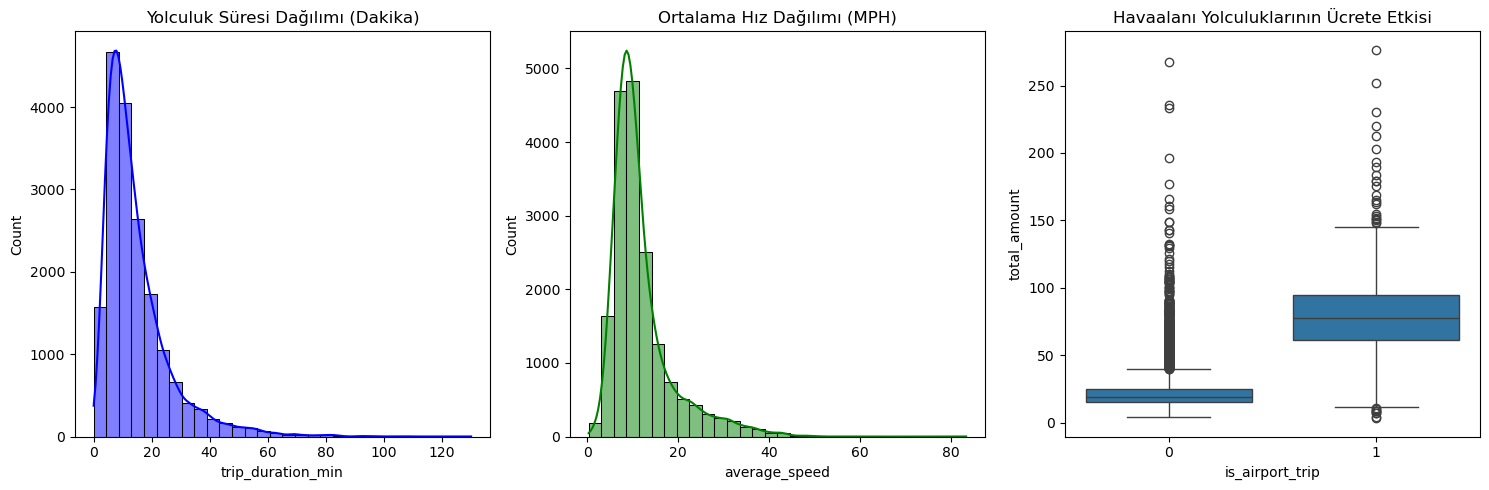

In [4]:
# Örneklem alarak görselleştirme yapalım (Spark -> Pandas)
sample_pdf = features_df.select("trip_duration_min", "average_speed", "total_amount", "is_airport_trip", "pickup_hour").sample(0.01).toPandas()

plt.figure(figsize=(15, 5))

# 1. Yolculuk Süresi Dağılımı
plt.subplot(1, 3, 1)
sns.histplot(sample_pdf['trip_duration_min'], bins=30, kde=True, color='blue')
plt.title('Yolculuk Süresi Dağılımı (Dakika)')

# 2. Ortalama Hız Dağılımı
plt.subplot(1, 3, 2)
sns.histplot(sample_pdf['average_speed'], bins=30, kde=True, color='green')
plt.title('Ortalama Hız Dağılımı (MPH)')

# 3. Havaalanı Yolculuğu vs Ücret
plt.subplot(1, 3, 3)
sns.boxplot(x='is_airport_trip', y='total_amount', data=sample_pdf)
plt.title('Havaalanı Yolculuklarının Ücrete Etkisi')

plt.tight_layout()
plt.show()

## 4. Korelasyon Analizi
Yeni özelliklerin hedef değişkenle korelasyonuna bakalım.

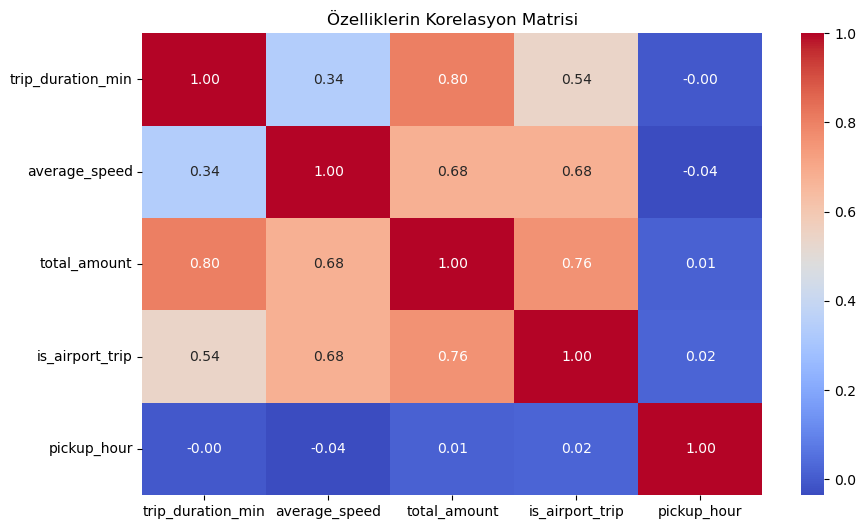

In [5]:
plt.figure(figsize=(10, 6))
corr = sample_pdf.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Özelliklerin Korelasyon Matrisi')
plt.show()

## 5. Sonuçların Kaydedilmesi
Elde ettiğimiz zenginleştirilmiş veri setini `data/delta/features` (Gold Layer) olarak kaydediyoruz. Bu tablo, Adım 6'da model eğitiminde kullanılacaktır.

In [6]:
output_path = "/home/jovyan/work/data/delta/features"
features_df.write.format("delta").mode("overwrite").save(output_path)
print(f"🚀 Gold Katmanı Başarıyla Oluşturuldu: {output_path}")

🚀 Gold Katmanı Başarıyla Oluşturuldu: /home/jovyan/work/data/delta/features


In [7]:
# Verinin başarıyla yazıldığını kontrol edelim
check_df = spark.read.format("delta").load("/home/jovyan/work/data/delta/features")
print(f"Toplam kayıt sayısı: {check_df.count()}")
check_df.show(5)


Toplam kayıt sayısı: 1798960
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+-----------------+-------------+-----------+-----------+---------------+------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|trip_duration_min|average_speed|pickup_hour|day_of_week|is_airport_trip|is_rush_hour|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-